In [1]:
import os
from pathlib import Path


# Make sure we are in the root directory
def set_project_root(marker="pyproject.toml"):
    """Change the working directory to the repository root."""
    path = Path.cwd()
    for parent in [path, *path.parents]:
        if (parent / marker).exists():
            os.chdir(parent)
            return parent
    raise FileNotFoundError(f"Could not find {marker} in any parent directory")

set_project_root()

import pandas as pd

In [15]:
from implementations.tabular_data.haoli_implementation.utils import extract_data_from_pkl
from implementations.tabular_data.haoli_implementation.utils import read_json_file
input_path = Path("implementations/tabular_data/single_table/results/models/None_trans_ckpt.pkl")
file=extract_data_from_pkl(input_path);
file

ClavaDDPMModelArtifacts(diffusion=GaussianMultinomialDiffusion(
  (_denoise_fn): MLPDiffusion(
    (mlp): MLP(
      (blocks): ModuleList(
        (0): Block(
          (linear): Linear(in_features=128, out_features=512, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (1): Block(
          (linear): Linear(in_features=512, out_features=1024, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (2-4): 3 x Block(
          (linear): Linear(in_features=1024, out_features=1024, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (5): Block(
          (linear): Linear(in_features=1024, out_features=512, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.0, inplace=False)
        )
      )
      (head): Linear(in_features=512, out_features=36, bias=True)
    )
    (proj): Linear(in_features=

In [5]:
import pandas as pd
file_csv_path = Path("implementations/tabular_data/single_table/results/single_table_synthesizing/trans/_final/trans_synthetic.csv")
file_csv = pd.read_csv(file_csv_path)
file_csv

,trans_date,trans_type,operation,amount,balance,k_symbol,bank,account
0,1974.263539,2,4,736.129694,31302.398252,0,0,0.000000e+00
1,1241.116120,2,4,14.600000,23037.408600,6,0,0.000000e+00
2,1048.000000,0,3,20567.336623,109235.826948,0,0,0.000000e+00
3,834.794125,0,0,91.432443,22406.704470,7,0,0.000000e+00
4,1626.000000,0,0,115.426567,28076.469350,7,0,0.000000e+00
...,...,...,...,...,...,...,...,...
15995,1822.770531,0,3,7925.028095,56588.530115,0,0,0.000000e+00
15996,948.621561,2,1,8692.514311,40942.457101,5,8,7.007198e+07
15997,2144.000000,2,1,121.469509,18783.439696,1,5,1.204854e+06
15998,1841.000000,2,4,14.600000,49664.158351,6,0,0.000000e+00


In [12]:
import numpy as np
file_csv['trans_date'].to_numpy().mean()

np.float64(1446.3993156118543)

In [17]:
encoder_rows = []

for column_index, encoder in sorted(file.label_encoders.items()):
    column_name = file.table_metadata.categorical_column_names[column_index]

    for encoded_value, original_value in enumerate(encoder.classes_):
        encoder_rows.append({
            "column": column_name,
            "encoded_value": encoded_value,
            "original_value": original_value,
        })

encoder_info = pd.DataFrame(encoder_rows)
encoder_info

,column,encoded_value,original_value
0,trans_type,0,0
1,trans_type,1,1
2,trans_type,2,2
3,operation,0,0
4,operation,1,1
5,operation,2,2
6,operation,3,3
7,operation,4,4
8,operation,5,5
9,k_symbol,0,0


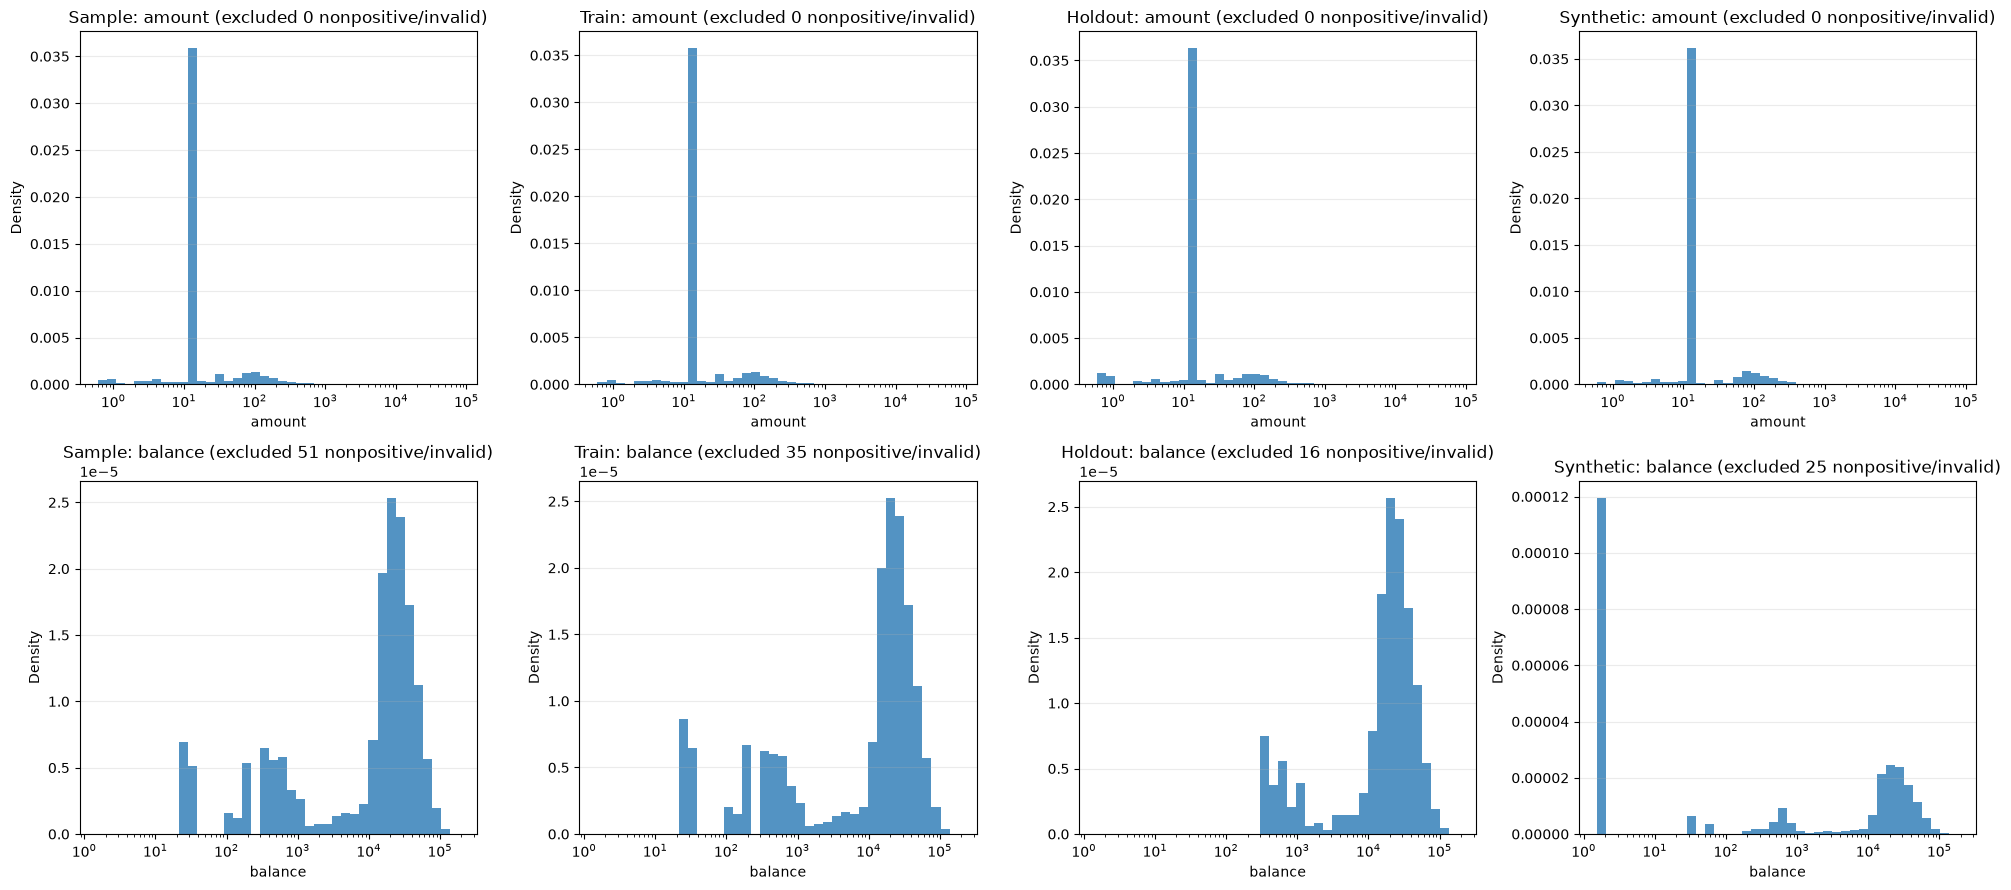

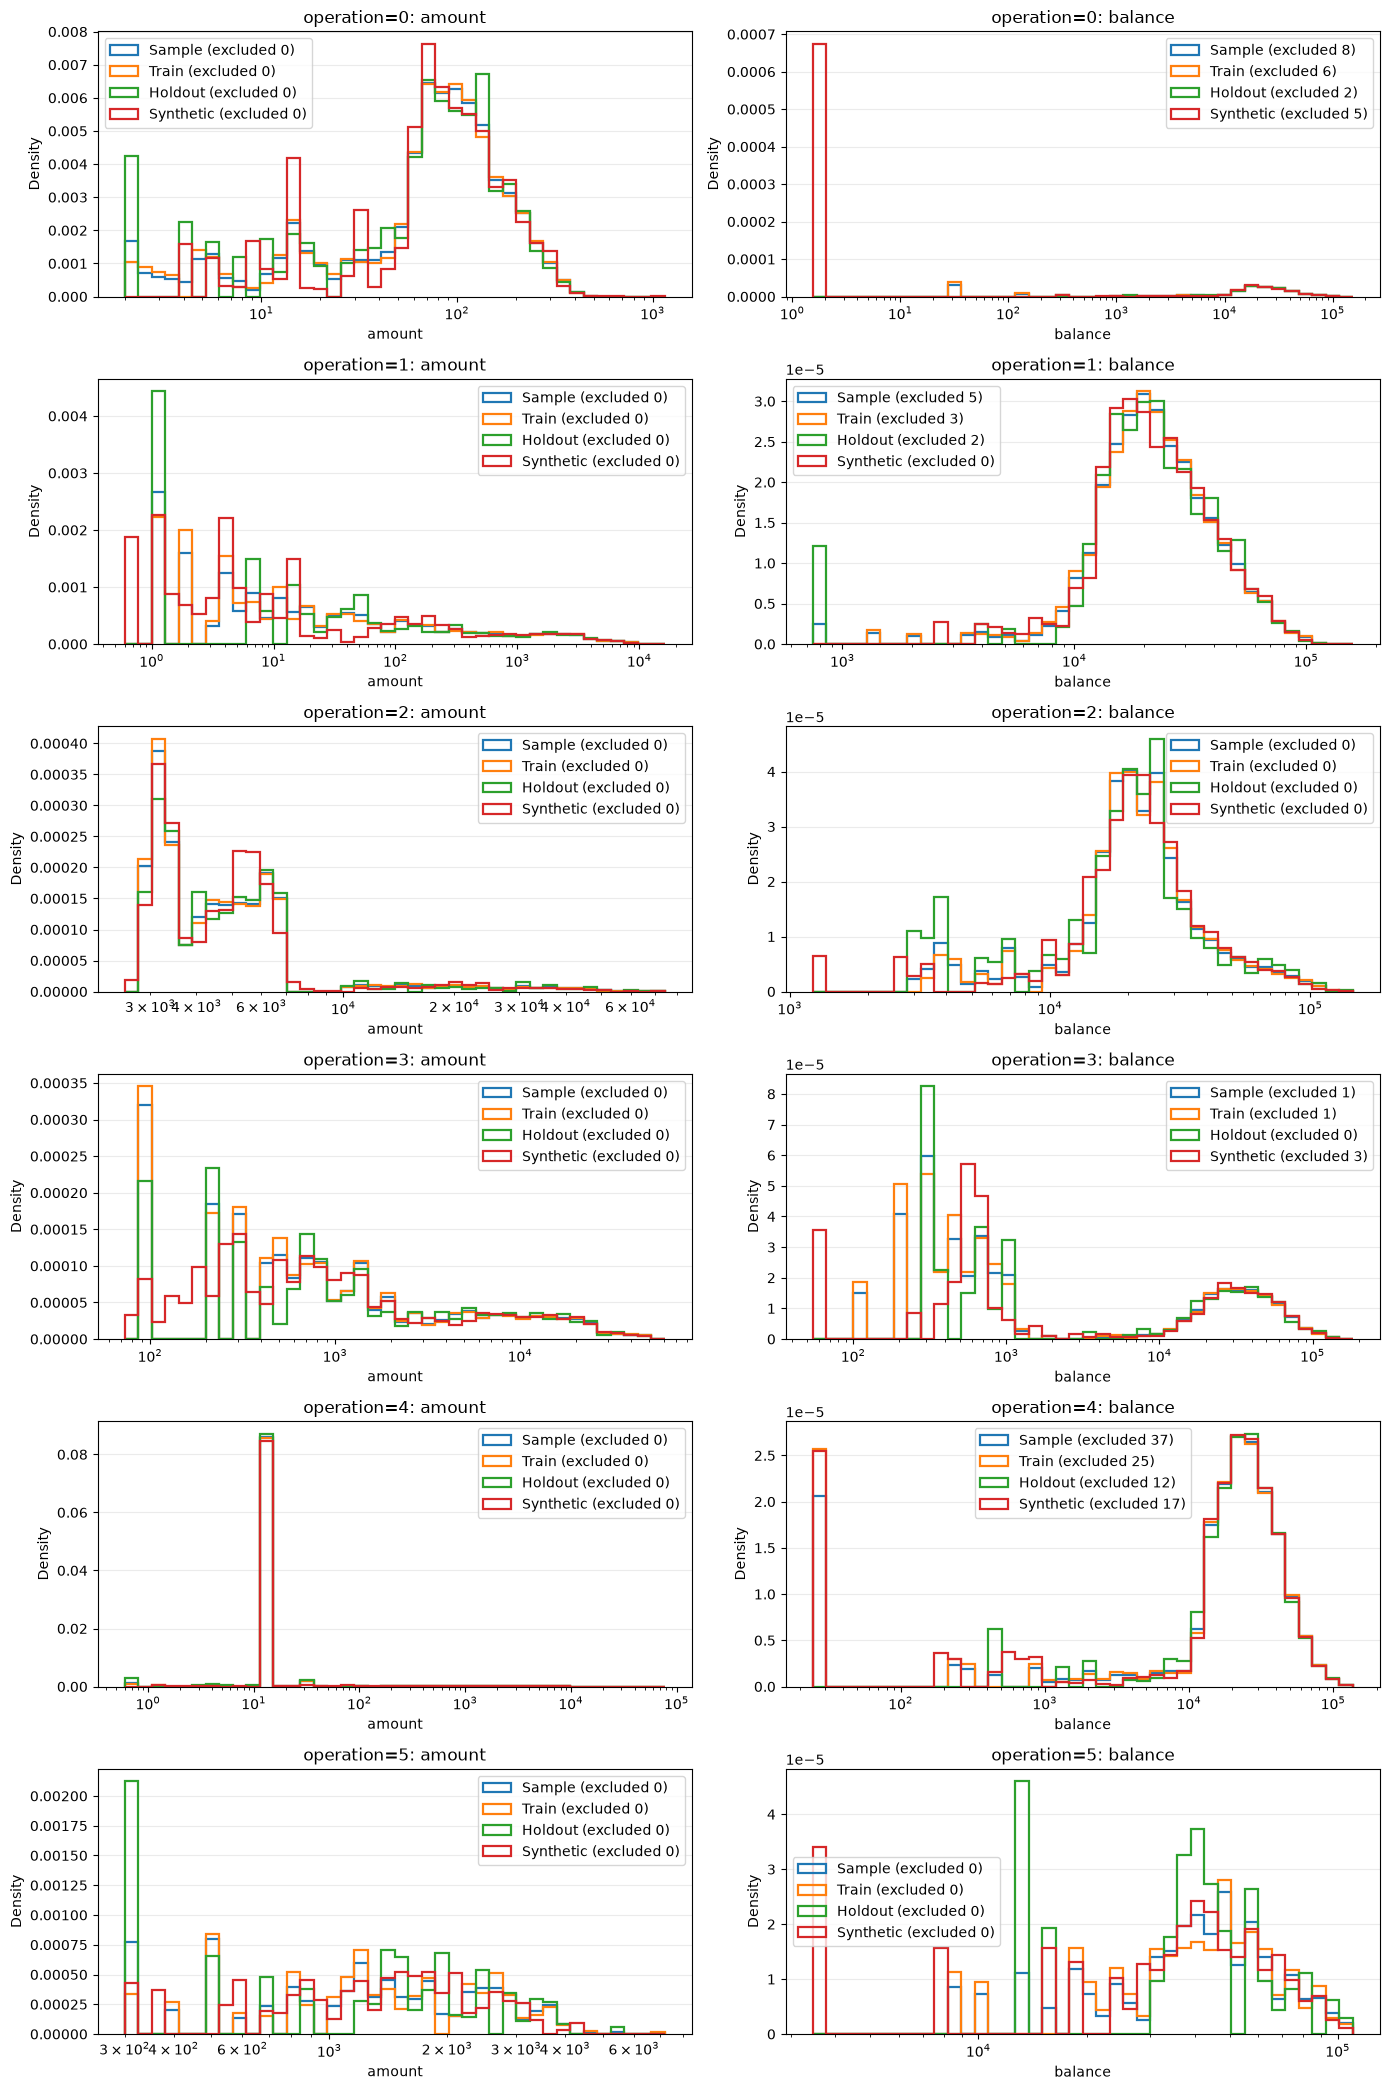

In [19]:
import matplotlib.pyplot as plt


data_dir = Path("implementations/tabular_data/single_table/data")
train_df = pd.read_csv(data_dir / "trans.csv")
holdout_df = pd.read_csv(data_dir / "trans_holdout.csv")
sample_df = pd.concat([train_df, holdout_df], ignore_index=True)

frames = {
    "Sample": sample_df,
    "Train": train_df,
    "Holdout": holdout_df,
    "Synthetic": file_csv,
}
features = ["amount", "balance"]


def positive_values(frame, column):
    values = pd.to_numeric(frame[column], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(values) & (values > 0)
    return values[valid], int((~valid).sum())


def shared_log_bins(frame_groups, column, bins=40):
    positive = [positive_values(frame, column)[0] for frame in frame_groups]
    positive = [values for values in positive if values.size]
    if not positive:
        return None

    values = np.concatenate(positive)
    lower, upper = values.min(), values.max()
    if lower == upper:
        lower, upper = lower / 1.001, upper * 1.001
    return np.geomspace(lower, upper, bins + 1)


# Overall amount and balance distributions across the sample, splits, and synthetic data.
fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex="row")
for row, feature in enumerate(features):
    bins = shared_log_bins(frames.values(), feature)
    for column, (frame_name, frame) in enumerate(frames.items()):
        ax = axes[row, column]
        values, excluded = positive_values(frame, feature)
        if values.size and bins is not None:
            ax.hist(values, bins=bins, density=True, color="#2878B5", alpha=0.8)
        else:
            ax.text(0.5, 0.5, "No positive values", ha="center", va="center", transform=ax.transAxes)
        ax.set_xscale("log")
        ax.set_title(f"{frame_name}: {feature} (excluded {excluded} nonpositive/invalid)")
        ax.set_xlabel(feature)
        ax.set_ylabel("Density")
        ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


# Compare the same distributions separately for each encoded operation value.
operation_values = pd.concat(
    [pd.to_numeric(frame["operation"], errors="coerce") for frame in frames.values()],
    ignore_index=True,
).dropna().unique()
operation_values = sorted(operation_values)
fig, axes = plt.subplots(len(operation_values), 2, figsize=(14, 3.5 * len(operation_values)), squeeze=False)
for row, operation_value in enumerate(operation_values):
    operation_frames = {}
    for frame_name, frame in frames.items():
        operation_codes = pd.to_numeric(frame["operation"], errors="coerce")
        operation_frames[frame_name] = frame.loc[operation_codes == operation_value]

    for column, feature in enumerate(features):
        ax = axes[row, column]
        bins = shared_log_bins(operation_frames.values(), feature)
        for frame_name, frame in operation_frames.items():
            values, excluded = positive_values(frame, feature)
            if values.size and bins is not None:
                ax.hist(
                    values,
                    bins=bins,
                    density=True,
                    histtype="step",
                    linewidth=1.6,
                    label=f"{frame_name} (excluded {excluded})",
                )
        ax.set_xscale("log")
        ax.set_title(f"operation={operation_value}: {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Density")
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
fig.tight_layout()
plt.show()

Statistical Assessment

### 1) Tail Quantile Error

- Formula:

  - `Err_q95 = |q95_syn - q95_real| / q95_real`

  - `Err_q99 = |q99_syn - q99_real| / q99_real`

- Default thresholds:

  - Pass if `Err_q95 <= 0.10`

  - Pass if `Err_q99 <= 0.15`

 

### 2) Tail Mass Ratio

- Formula:

  - `TMR95 = P_syn(amount >= q95_real) / P_real(amount >= q95_real)`

  - `TMR99 = P_syn(amount >= q99_real) / P_real(amount >= q99_real)`

- Default thresholds:

  - Pass if `0.80 <= TMR95 <= 1.20`

  - Pass if `0.70 <= TMR99 <= 1.30`

 

### 3) Tail Distribution Distance (Upper Tail)

- Slice: rows where `amount >= q95_real`

- Formula:

  - `KS95 = KS(real_tail95.amount, syn_tail95.amount)`

  - Optional: `W95 = Wasserstein(real_tail95.amount, syn_tail95.amount)`

- Default thresholds:

  - Pass if `KS95 <= 0.12`

  - Optional pass if `W95 <= 0.20 * std(real_tail95.amount)`

 

### 4) Rare Type Frequency Error

- For each rare type `t in R`:

  - `FreqErr(t) = |p_syn(t) - p_real(t)|`

- Aggregate:

  - `MAE_rare = mean_{t in R}(FreqErr(t))`

- Default thresholds:

  - Pass if `MAE_rare <= 0.01`

  - No individual rare type with `FreqErr(t) > 0.03`

 

### 5) Rare Type Coverage

- Formula:

  - `Coverage_rare = |{t in R : count_syn(t) > 0}| / |R|`

- Default threshold:

  - Pass if `Coverage_rare >= 0.95`

 

### 6) Rare Pair Co-Occurrence Preservation (Optional)

- Build rare pair set `P` from real where pair support in `[min_sup, max_sup]`

- Formula:

  - `PairMAE = mean_{p in P} |p_syn(p) - p_real(p)|`

- Default threshold:

  - Pass if `PairMAE <= 0.005`

 

### 7) Fraud Utility Proxy (Model-to-Model Transfer)

Train the same classifier twice:

- Model A: train on real train, eval on real holdout

- Model B: train on synthetic, eval on real holdout

 

Use PR-AUC (or Recall@K for severe imbalance).

- Formula:

  - `UtilityGap = (Metric_A - Metric_B) / Metric_A`

- Default threshold:

  - Pass if `UtilityGap <= 0.10`

In [ ]:
from scipy.stats import ks_2samp

real_amount = pd.to_numeric(holdout_df["amount"], errors="coerce").to_numpy(dtype=float)
synthetic_amount = pd.to_numeric(file_csv["amount"], errors="coerce").to_numpy(dtype=float)
real_amount = real_amount[np.isfinite(real_amount)]
synthetic_amount = synthetic_amount[np.isfinite(synthetic_amount)]

if not real_amount.size or not synthetic_amount.size:
    raise ValueError("Real holdout and synthetic data must both contain finite amount values.")

q95_real, q99_real = np.quantile(real_amount, [0.95, 0.99])
q95_synthetic, q99_synthetic = np.quantile(synthetic_amount, [0.95, 0.99])
err_95 = abs(q95_synthetic - q95_real) / abs(q95_real) if q95_real else np.nan
err_99 = abs(q99_synthetic - q99_real) / abs(q99_real) if q99_real else np.nan


def calculate_tail_metrics(threshold):
    real_tail = real_amount[real_amount >= threshold]
    synthetic_tail = synthetic_amount[synthetic_amount >= threshold]
    p_real = real_tail.size / real_amount.size
    p_synthetic = synthetic_tail.size / synthetic_amount.size
    tmr = p_synthetic / p_real if p_real else np.nan
    ks = ks_2samp(real_tail, synthetic_tail).statistic if real_tail.size and synthetic_tail.size else np.nan
    return p_real, p_synthetic, tmr, ks


p_real_95, p_synthetic_95, tmr_95, ks_95 = calculate_tail_metrics(q95_real)
p_real_99, p_synthetic_99, tmr_99, ks_99 = calculate_tail_metrics(q99_real)


def pass_status(value, passed):
    if not np.isfinite(value):
        return "NOT TESTABLE"
    return "PASS" if passed else "FAIL"


err_95_status = pass_status(err_95, err_95 <= 0.10)
err_99_status = pass_status(err_99, err_99 <= 0.15)
tmr_95_status = pass_status(tmr_95, 0.80 <= tmr_95 <= 1.20)
tmr_99_status = pass_status(tmr_99, 0.70 <= tmr_99 <= 1.30)
ks_95_status = pass_status(ks_95, ks_95 <= 0.12)

results = pd.DataFrame([
    {"Metric": "p_95", "Real": q95_real, "Synthetic": q95_synthetic, "Test result": np.nan, "Threshold": "Reference quantiles", "Status": "N/A"},
    {"Metric": "p_99", "Real": q99_real, "Synthetic": q99_synthetic, "Test result": np.nan, "Threshold": "Reference quantiles", "Status": "N/A"},
    {"Metric": "Err_95", "Real": np.nan, "Synthetic": np.nan, "Test result": err_95, "Threshold": "<= 0.10", "Status": err_95_status},
    {"Metric": "Err_99", "Real": np.nan, "Synthetic": np.nan, "Test result": err_99, "Threshold": "<= 0.15", "Status": err_99_status},
    {"Metric": "TMR95", "Real": p_real_95, "Synthetic": p_synthetic_95, "Test result": tmr_95, "Threshold": "0.80 to 1.20", "Status": tmr_95_status},
    {"Metric": "TMR99", "Real": p_real_99, "Synthetic": p_synthetic_99, "Test result": tmr_99, "Threshold": "0.70 to 1.30", "Status": tmr_99_status},
    {"Metric": "KS95", "Real": np.nan, "Synthetic": np.nan, "Test result": ks_95, "Threshold": "<= 0.12", "Status": ks_95_status}
])

print(f"Real comparison set: holdout_df ({real_amount.size} finite amount values)")
print(f"Synthetic comparison set: file_csv ({synthetic_amount.size} finite amount values)")
print(results.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

threshold_statuses = [err_95_status, err_99_status, tmr_95_status, tmr_99_status, ks_95_status]
if "NOT TESTABLE" in threshold_statuses:
    overall_status = "NOT TESTABLE"
else:
    overall_status = "PASS" if all(value == "PASS" for value in threshold_statuses) else "FAIL"
print(f"Overall status for metrics with defined thresholds: {overall_status}")

Real comparison set: holdout_df (4000 finite amount values)
Synthetic comparison set: file_csv (16000 finite amount values)
Metric         Real    Synthetic  Test result                 Threshold        Status
  p_95 26019.750000 24591.199941          NaN       Reference quantiles           N/A
  p_99 46901.000000 44660.517450          NaN       Reference quantiles           N/A
Err_95          NaN          NaN     0.054903                   <= 0.10          PASS
Err_99          NaN          NaN     0.047770                   <= 0.15          PASS
 TMR95     0.050000     0.045125     0.902500              0.80 to 1.20          PASS
 TMR99     0.010000     0.007250     0.725000              0.70 to 1.30          PASS
  KS95          NaN          NaN     0.058019                   <= 0.12          PASS
  KS99          NaN          NaN     0.162931 Not specified in markdown NOT SPECIFIED
Overall status for metrics with defined thresholds: PASS
